In [1]:
import numpy as np
import scanpy as sc
import pandas as pd
from tqdm import tqdm
from pprint import pprint

sc.set_figure_params(frameon=False, dpi=80, fontsize=12)

from utils.io import read_anndata, write_zarr
from utils.misc import dask_compute

/hpc/scratch/project.hca_integration/miniforge3/envs/scanpy/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
/hpc/scratch/project.hca_integration/miniforge3/envs/scanpy/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing read_elem from `anndata.experimental` is deprecated. Import anndata.io.read_elem instead.
  warnings.warn(msg, FutureWarning)
/hpc/scratch/project.hca_integration/miniforge3/envs/scanpy/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing sparse_dataset from `anndata.experimental` is deprecated. Import anndata.io.sparse_dataset instead.
  warnings.warn(msg, FutureWarning)


# Read Data

In [11]:
adata = read_anndata(
    'data/pipeline/qc/qc/dataset~HLCA_AT2_qc/file_id~relabel:filter:doublets:HLCA.zarr',
    X='X',
    layers='layers',
    obs='obs',
    var='var',
    obsm='obsm',
    uns='uns',
    obsp='obsp',
    dask=True,
    backed=True,
)

dask: True, backed: True
chunks: (200000, -1)
Read slot "X", store as "X"...
Read X as backed sparse dask array...
shape: (584944, 27957)
Read slot "layers", store as "layers"...


/hpc/scratch/project.hca_integration/miniforge3/envs/scanpy/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing CSRDataset from `anndata.experimental` is deprecated. Import anndata.abc.CSRDataset instead.
  warnings.warn(msg, FutureWarning)
/hpc/scratch/project.hca_integration/miniforge3/envs/scanpy/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing CSCDataset from `anndata.experimental` is deprecated. Import anndata.abc.CSCDataset instead.
  warnings.warn(msg, FutureWarning)
Read layers slots as_dask=True: 100%|██████████| 2/2 [00:00<00:00, 56.64it/s]

Read slot "obs", store as "obs"...


shape: (62405, 87)
Read slot "var", store as "var"...
shape: (27957, 6)
Read slot "obsm", store as "obsm"...


Read obsm slots as_dask=False: 100%|██████████| 3/3 [00:00<00:00,  5.37it/s]

Read slot "uns", store as "uns"...
Read slot "obsp", store as "obsp"...



Read obsp slots as_dask=False: 100%|██████████| 2/2 [00:01<00:00,  1.73it/s]

shape: (62405, 27957)


In [12]:
adata

AnnData object with n_obs × n_vars = 62405 × 27957
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'sex_ontology_term_id', 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'dataset', 'entropy_dataset_leiden_3', 'entropy_original_ann_level_1_leiden_3', 'entropy_original_ann_level_2_clean_leiden_3', 'entropy_original_ann_level_3_clean_leiden_3', 'entropy_subject_ID_leiden_3', 'fresh_or_frozen', 'leiden_1', 'leiden_2', 'leiden_3', 'leiden_4', 'leiden_5', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'n_genes_detected', 'original_ann_highest_res', 'original_ann_level_1', 'original_ann_level_2', 'origin

# UMAP sanity check

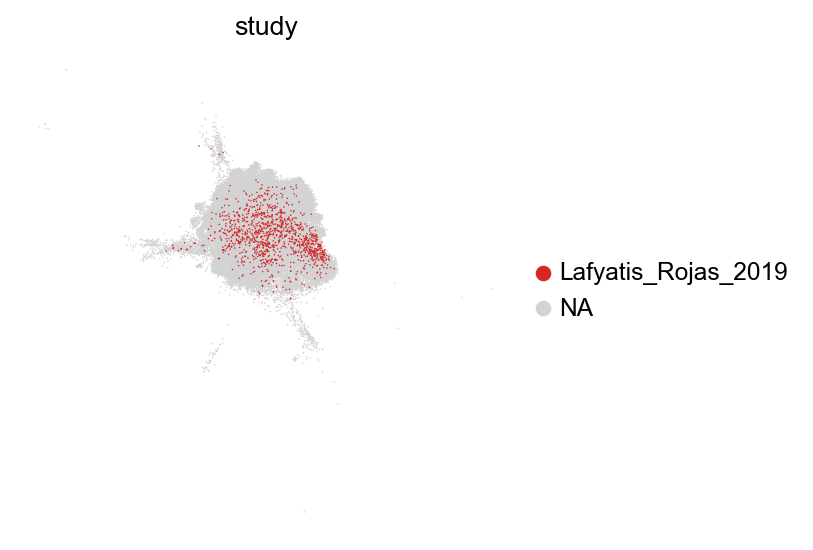

In [14]:
sc.pl.umap(
        adata,
        color='study',
        groups='Lafyatis_Rojas_2019',
        ncols=1,
    )

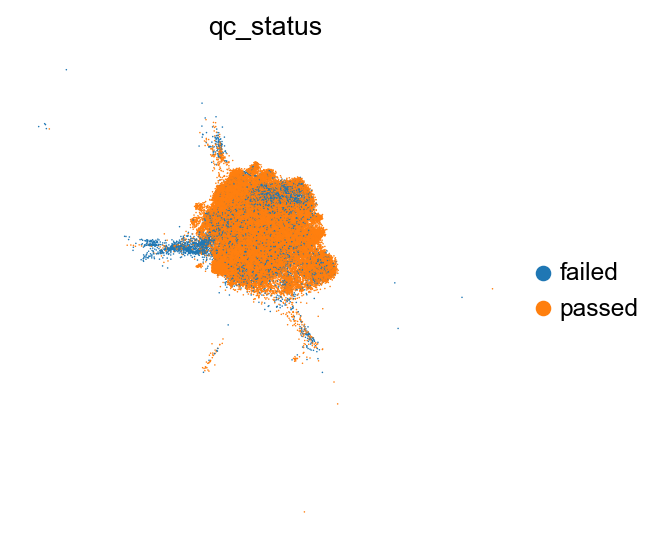

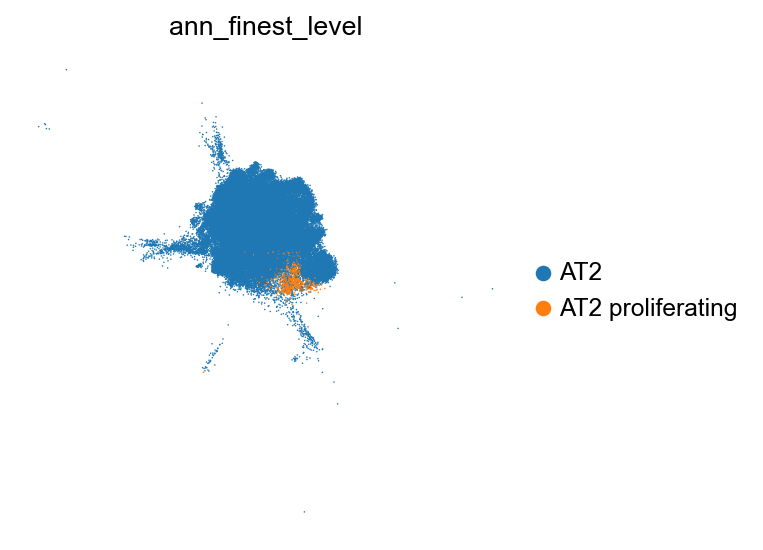

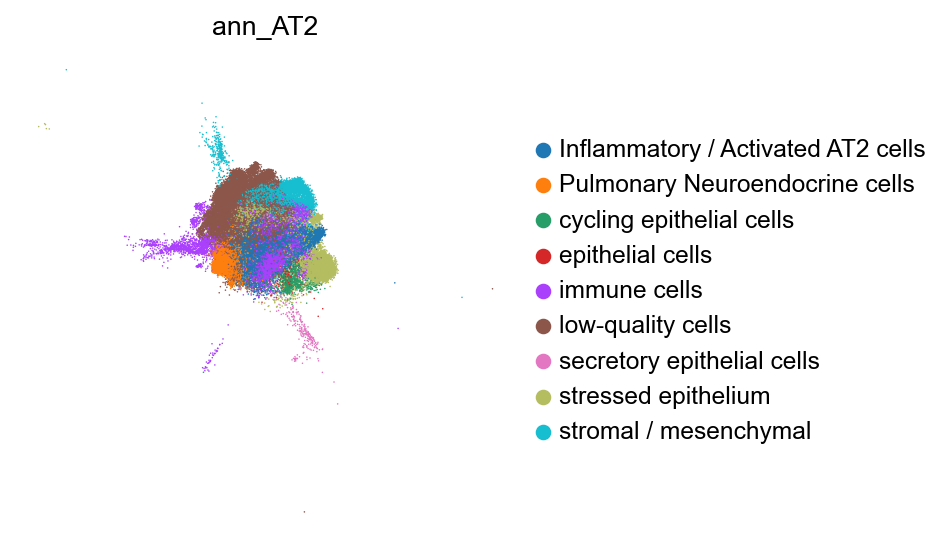

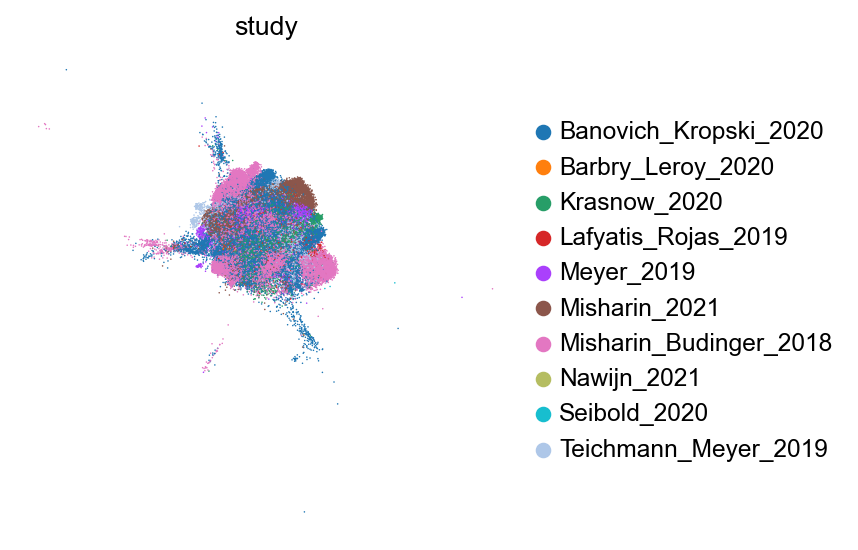

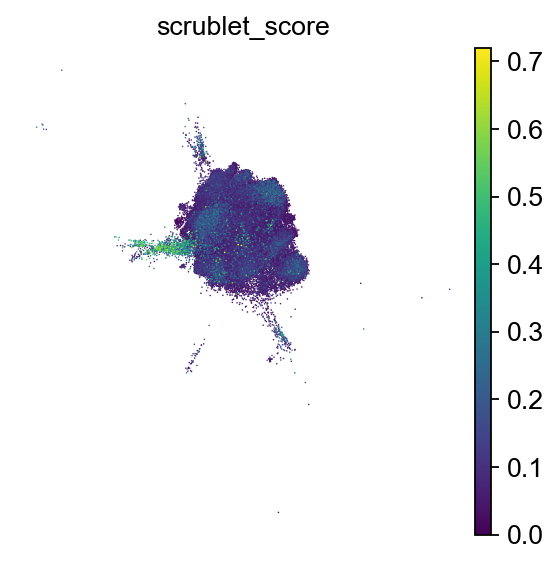

In [15]:
for color in ['qc_status', 'ann_finest_level', 'ann_AT2', 'study', 'scrublet_score']:
    sc.pl.umap(
        adata,
        color=color,
        ncols=1,
    )

# Export

In [13]:
adata = dask_compute(adata)

Apply function compute_layer to X...


Dask compute:   0%|          | 0/7 [00:00<?, ?it/s]

Apply function compute_layer to raw...
Apply function compute_layer to counts...


Dask compute:   0%|          | 0/7 [00:00<?, ?it/s]

Apply function compute_layer to orig_normcounts...


Dask compute:   0%|          | 0/7 [00:00<?, ?it/s]

In [6]:
output_dir = 'data/output/export'
file_name = 'hlca_at2_qc.h5ad'

In [7]:
%%time
adata.write_h5ad(f'{output_dir}/{file_name}', compression='lzf')

CPU times: user 8.7 s, sys: 1.49 s, total: 10.2 s
Wall time: 10.2 s


In [8]:
!echo rclone copy -P {output_dir}/{file_name} onedrive:scAtlasTb/HLCA

rclone copy -P data/output/export/hlca_at2_qc.h5ad onedrive:scAtlasTb/HLCA
